In [1]:
"""
This notebook is to characterize DO bias in LiveOcean model, including Fig. 3 and 4 in the manuscript
"""

'\nThis notebook is to characterize DO bias in LiveOcean model, including Fig. 3 and 4 in the manuscript\n'

In [2]:
import pandas as pd
import numpy as np
import pickle
import gsw
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LogNorm
from matplotlib.ticker import AutoMinorLocator

# Set global font sizes for all plots, now all subsequent plots will follow these settings

plt.rcParams.update({
    'axes.labelsize': 14,
    # 'axes.labelweight': 'bold',
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'xtick.direction': 'out',
    'ytick.direction': 'in',
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 3,
    'ytick.minor.size': 3,
    'xtick.major.width': 1,
    'ytick.major.width': 1,
    'xtick.minor.width': 0.8,
    'ytick.minor.width': 0.8,
    'font.size': 12,
})

from lo_tools import plotting_functions as pfun

from lo_tools import Lfun
Ldir = Lfun.Lstart()

In [3]:
# where the date from 
in_dir = Ldir['LOo'] / 'LO_bias_corr' / 'data'/ 'processed'

# where to put output figures
fig_dir = Ldir['LOo'] / 'LO_bias_corr' / 'plots' / 'DO_bias_EDA'
Lfun.make_dir(fig_dir)

In [4]:
# two types of observation
otype_list = ['bottle', 'ctd']   
# otype_list = ['bottle']

gtx = 'cas2k_v4_lo2b'  # model name

remove_dfo = True   # this should be True all the time, unless later if including more CTD data at surface 30 m

full_z = True # if full_z, this needs to be True, filter_z needs to be False
filter_z = False  # if filter_z, True means 30-800m, False means below 30 m full_z needs to be False
surf_z = False # if above 30 m, this needs to be True, and both full_z and filter_z need to be False 

for otype in otype_list:
    if otype == 'bottle':
        in_fn = in_dir / ('combined_' + otype + '_all_' + '1993-2021' + '.p')
        bottle = pickle.load(open(in_fn, 'rb'))
        
        if filter_z and not full_z and not surf_z:
            Z = '30-800 m'
            mask = (bottle['obs']['z'] >= -800) & (bottle['obs']['z'] <= -30)
        elif not filter_z and not full_z and not surf_z:
            Z = 'below 30m'
            mask = (bottle['obs']['z'] < -30)
        elif surf_z and not filter_z and not full_z:
            Z = 'above 30m'
            mask = (bottle['obs']['z'] >= -30)
        elif full_z and not filter_z and not surf_z:
            Z = 'full_depth'
            mask = None  # no filters
        else:
            raise ValueError("Only one of full_z, filter_z, or surf_z should be True.")   
            
        # Apply mask 
        if mask is not None:
            bottle['obs'] = bottle['obs'][mask]
            bottle[gtx] = bottle[gtx][mask]                
                 
        # calculate DO bias  
        bias_bottle = bottle[gtx]['DO (uM)'] - bottle['obs']['DO (uM)']            
        
    if otype == 'ctd':
        in_fn = in_dir / ('combined_' + otype + '_all_' + '1998-2022' + '.p')
        ctd = pickle.load(open(in_fn, 'rb'))
        
        # for ctd dataset, remove dfo dataset, because the quality is a bit messy
        if remove_dfo:
            # Drop rows where 'source' is equal to 'dfo1'
            ctd['obs'] = ctd['obs'][ctd['obs']['source'] != 'dfo1']
            ctd[gtx] = ctd[gtx][ctd[gtx]['source'] != 'dfo1']
            
        # Filter by z 
        if filter_z and not full_z and not surf_z:
            Z = '30-800 m'
            mask = (ctd['obs']['z'] >= -800) & (ctd['obs']['z'] <= -30)
        elif not filter_z and not full_z and not surf_z:
            Z = 'below 30m'
            mask = (ctd['obs']['z'] < -30)
        elif surf_z and not filter_z and not full_z:
            Z = 'above 30m'
            mask = (ctd['obs']['z'] >= -30)
        elif full_z and not filter_z and not surf_z:
            Z = 'full_depth'
            mask = None
        else:
            raise ValueError("Only one of full_z, filter_z, or surf_z should be True.")
        
        # Apply filter
        if mask is not None:
            ctd['obs'] = ctd['obs'][mask]
            ctd[gtx] = ctd[gtx][mask]
        
        # Calculate DO bias
        bias_ctd = ctd[gtx]['DO (uM)'] - ctd['obs']['DO (uM)']
        
# combine ctd and bottle into one data  
if len(otype_list) == 2:
    # combine bottle and ctd       
    columns = list(set(bottle[gtx].columns).intersection(set(ctd[gtx].columns)))
    data = pd.concat([bottle[gtx][columns], ctd[gtx][columns]],ignore_index=True)
    
    bias = pd.DataFrame({
        'bias': pd.concat([bias_bottle, bias_ctd], ignore_index=True)
    })
else:
    data = bottle[gtx].copy()
    bias = pd.DataFrame({
        'bias': bias_bottle
    })

DO_obs = pd.DataFrame({
    'DO_obs': pd.concat([bottle['obs']['DO (uM)'], ctd['obs']['DO (uM)']], ignore_index=True)
})
# assign bias to data     
data['bias'] = bias['bias']
# get the water depth
data['z'] = (data['z'] * -1).round().astype(int)

data['DO_obs'] = DO_obs['DO_obs']
data['h'] = -data['h'].abs()
data['z_fraction_raw'] = data['z'].abs() / data['h'].abs()
data['z_fraction'] = data['z_fraction_raw'].clip(0, 1)
# remove HABRISE
data = data.loc[data['source'].ne('HABRISE')].copy()
# First perform point-level QC
data = data[data['DO_obs'] <= 400].copy()
# Create a new unique cast ID based on
# source + lat + lon + time
data['cid_new'] = (
    data.groupby(
        ['source', 'lat', 'lon', 'time'],
        sort=False
    ).ngroup() + 1
)
# Remove original cid
data = data.drop(columns='cid')
# Rename cid_new -> cid
data = data.rename(columns={'cid_new': 'cid'})

/tmp/ipykernel_1520331/1327227137.py:17: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/yifan/anaconda3/envs/bias/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


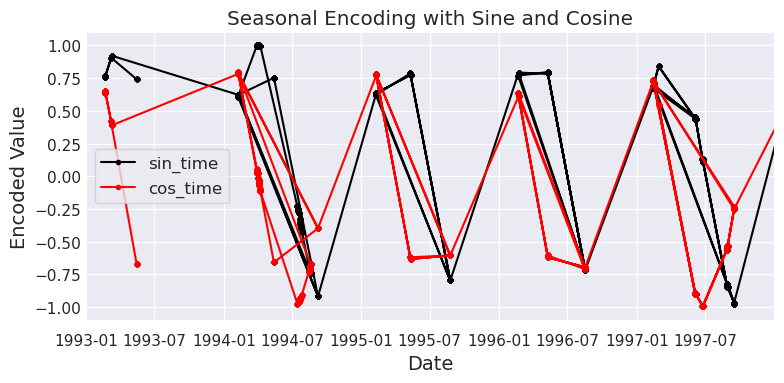

In [5]:
# convert time to numerical as time needs to be an input variable, day of year (1 to 365)
day_of_year = data['time'].dt.dayofyear
# Encode as sine and cosine
data['sin_t'] = np.sin(2 * np.pi * day_of_year / 365)
data['cos_t'] = np.cos(2 * np.pi * day_of_year / 365)

# day 90 (spring) and day 270 (fall) would both have cosine values near 0, but they are very different seasons
plt.figure(figsize=(8,4))
plt.plot(data['time'], data['sin_t'], marker = '.', linestyle = '-', color = 'black', label='sin_time')
plt.plot(data['time'], data['cos_t'], marker = '.', linestyle = '-', color = 'red',label='cos_time')
plt.title('Seasonal Encoding with Sine and Cosine')
plt.xlabel('Date')
plt.ylabel('Encoded Value')
plt.xlim(pd.Timestamp('1993-01-01'), pd.Timestamp('1997-12-31'))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [6]:
# choose predictors
vn = [
    'cid',
    'source',
    'time',
    'lon',
    'lat',
    'z',
    'h',
    'z_fraction',
    'cos_t',
    'sin_t',
    'CT',
    'SA',
    'DO (uM)',
    # 'NO3 (uM)',
    'bias',
]
df0 = data[vn]
# make a copy
df = df0.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1734196 entries, 0 to 1739240
Data columns (total 14 columns):
 #   Column      Dtype         
---  ------      -----         
 0   cid         int64         
 1   source      object        
 2   time        datetime64[ns]
 3   lon         float64       
 4   lat         float64       
 5   z           int64         
 6   h           float64       
 7   z_fraction  float64       
 8   cos_t       float64       
 9   sin_t       float64       
 10  CT          float64       
 11  SA          float64       
 12  DO (uM)     float64       
 13  bias        float64       
dtypes: datetime64[ns](1), float64(10), int64(2), object(1)
memory usage: 198.5+ MB


In [7]:
num = df.isna().sum()
print(f"Missing values in df:\n{num}")
# if there is nan, do
# df = df.dropna().reset_index(drop=True)

Missing values in df:
cid           0
source        0
time          0
lon           0
lat           0
z             0
h             0
z_fraction    0
cos_t         0
sin_t         0
CT            0
SA            0
DO (uM)       0
bias          0
dtype: int64


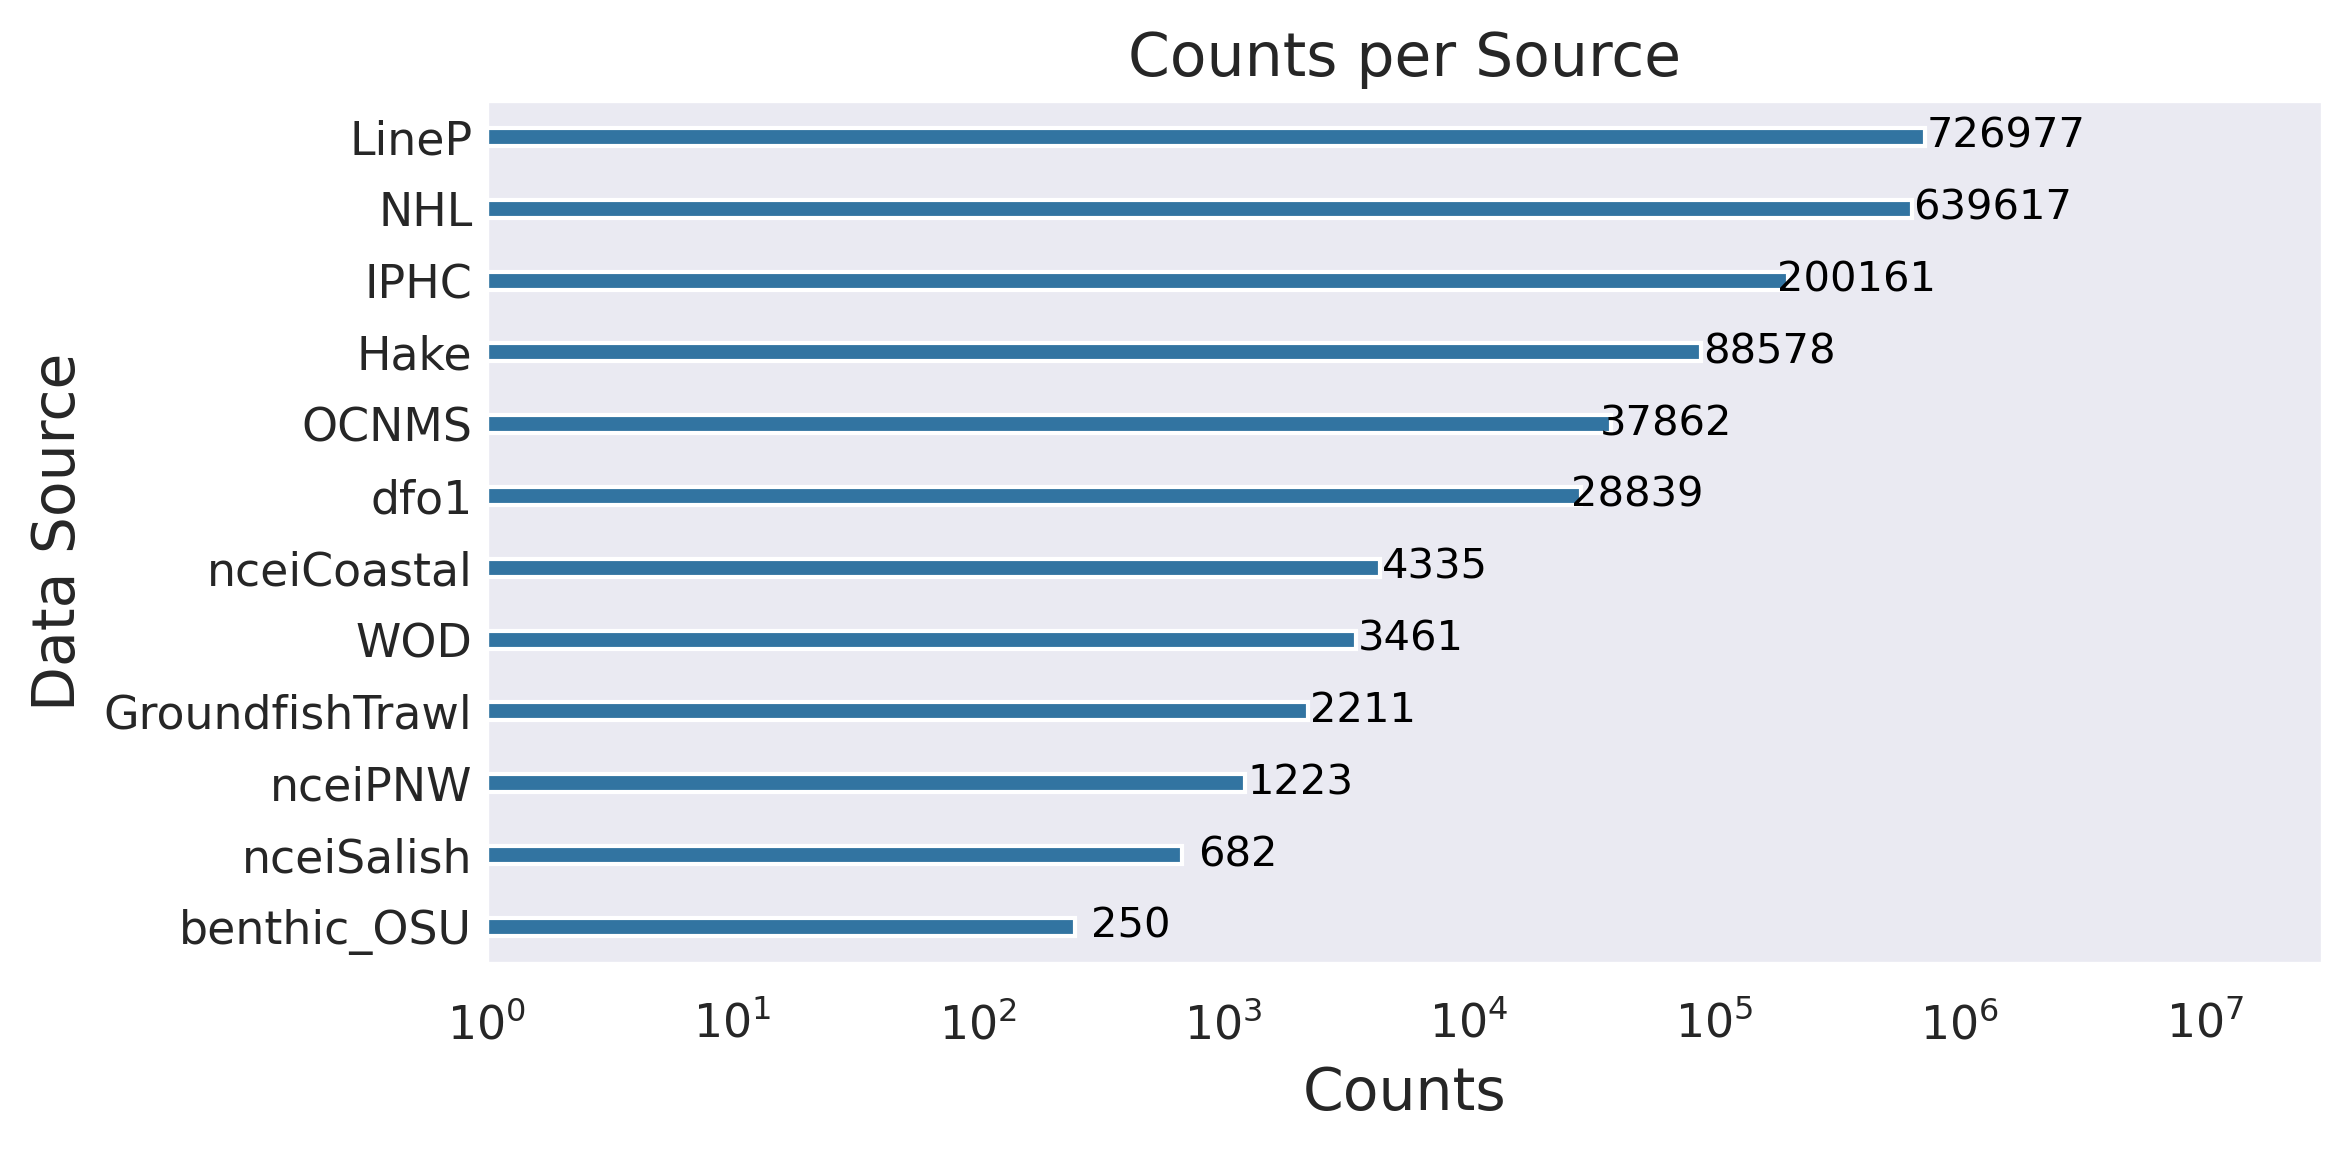

In [8]:
# plot the countplot
plt.close()  # Close any previous plots
# Add the count number as the title for the plot
count_per_source = df['source'].value_counts()
# Create a single countplot for all sources in one plot
plt.figure(figsize=(8, 4), dpi=300)
sns.countplot(data=df, y='source', width=0.25, order=count_per_source.index)

# Set the title to show counts for all sources
plt.title("Counts per Source")

# Set the y-axis to logarithmic scale
plt.xscale('log')

# Set the y-axis limits
plt.xlim([1, 3e7])

plt.ylabel("Data Source")
plt.xlabel("Counts")
plt.grid(False)
# add count numbers on top of the bars
for i, p in enumerate(plt.gca().patches):
    width = p.get_width()
    # first two bars
    if i < 2:
        offset = (9, 0)
    elif i >= 2 and i <= 3:
        offset = (6, 0)
    else:
        offset = (3, 0)
    plt.gca().annotate(
        f'{int(width)}',
        (width * 1.5, p.get_y() + p.get_height() / 2.),
        ha='center',
        va='center',
        fontsize=10,
        color='black',
        xytext=offset,
        textcoords='offset points'
    )
plt.tight_layout()
plt.savefig(f'{fig_dir}/EDA_count_plot_z={Z}.png')
plt.show()


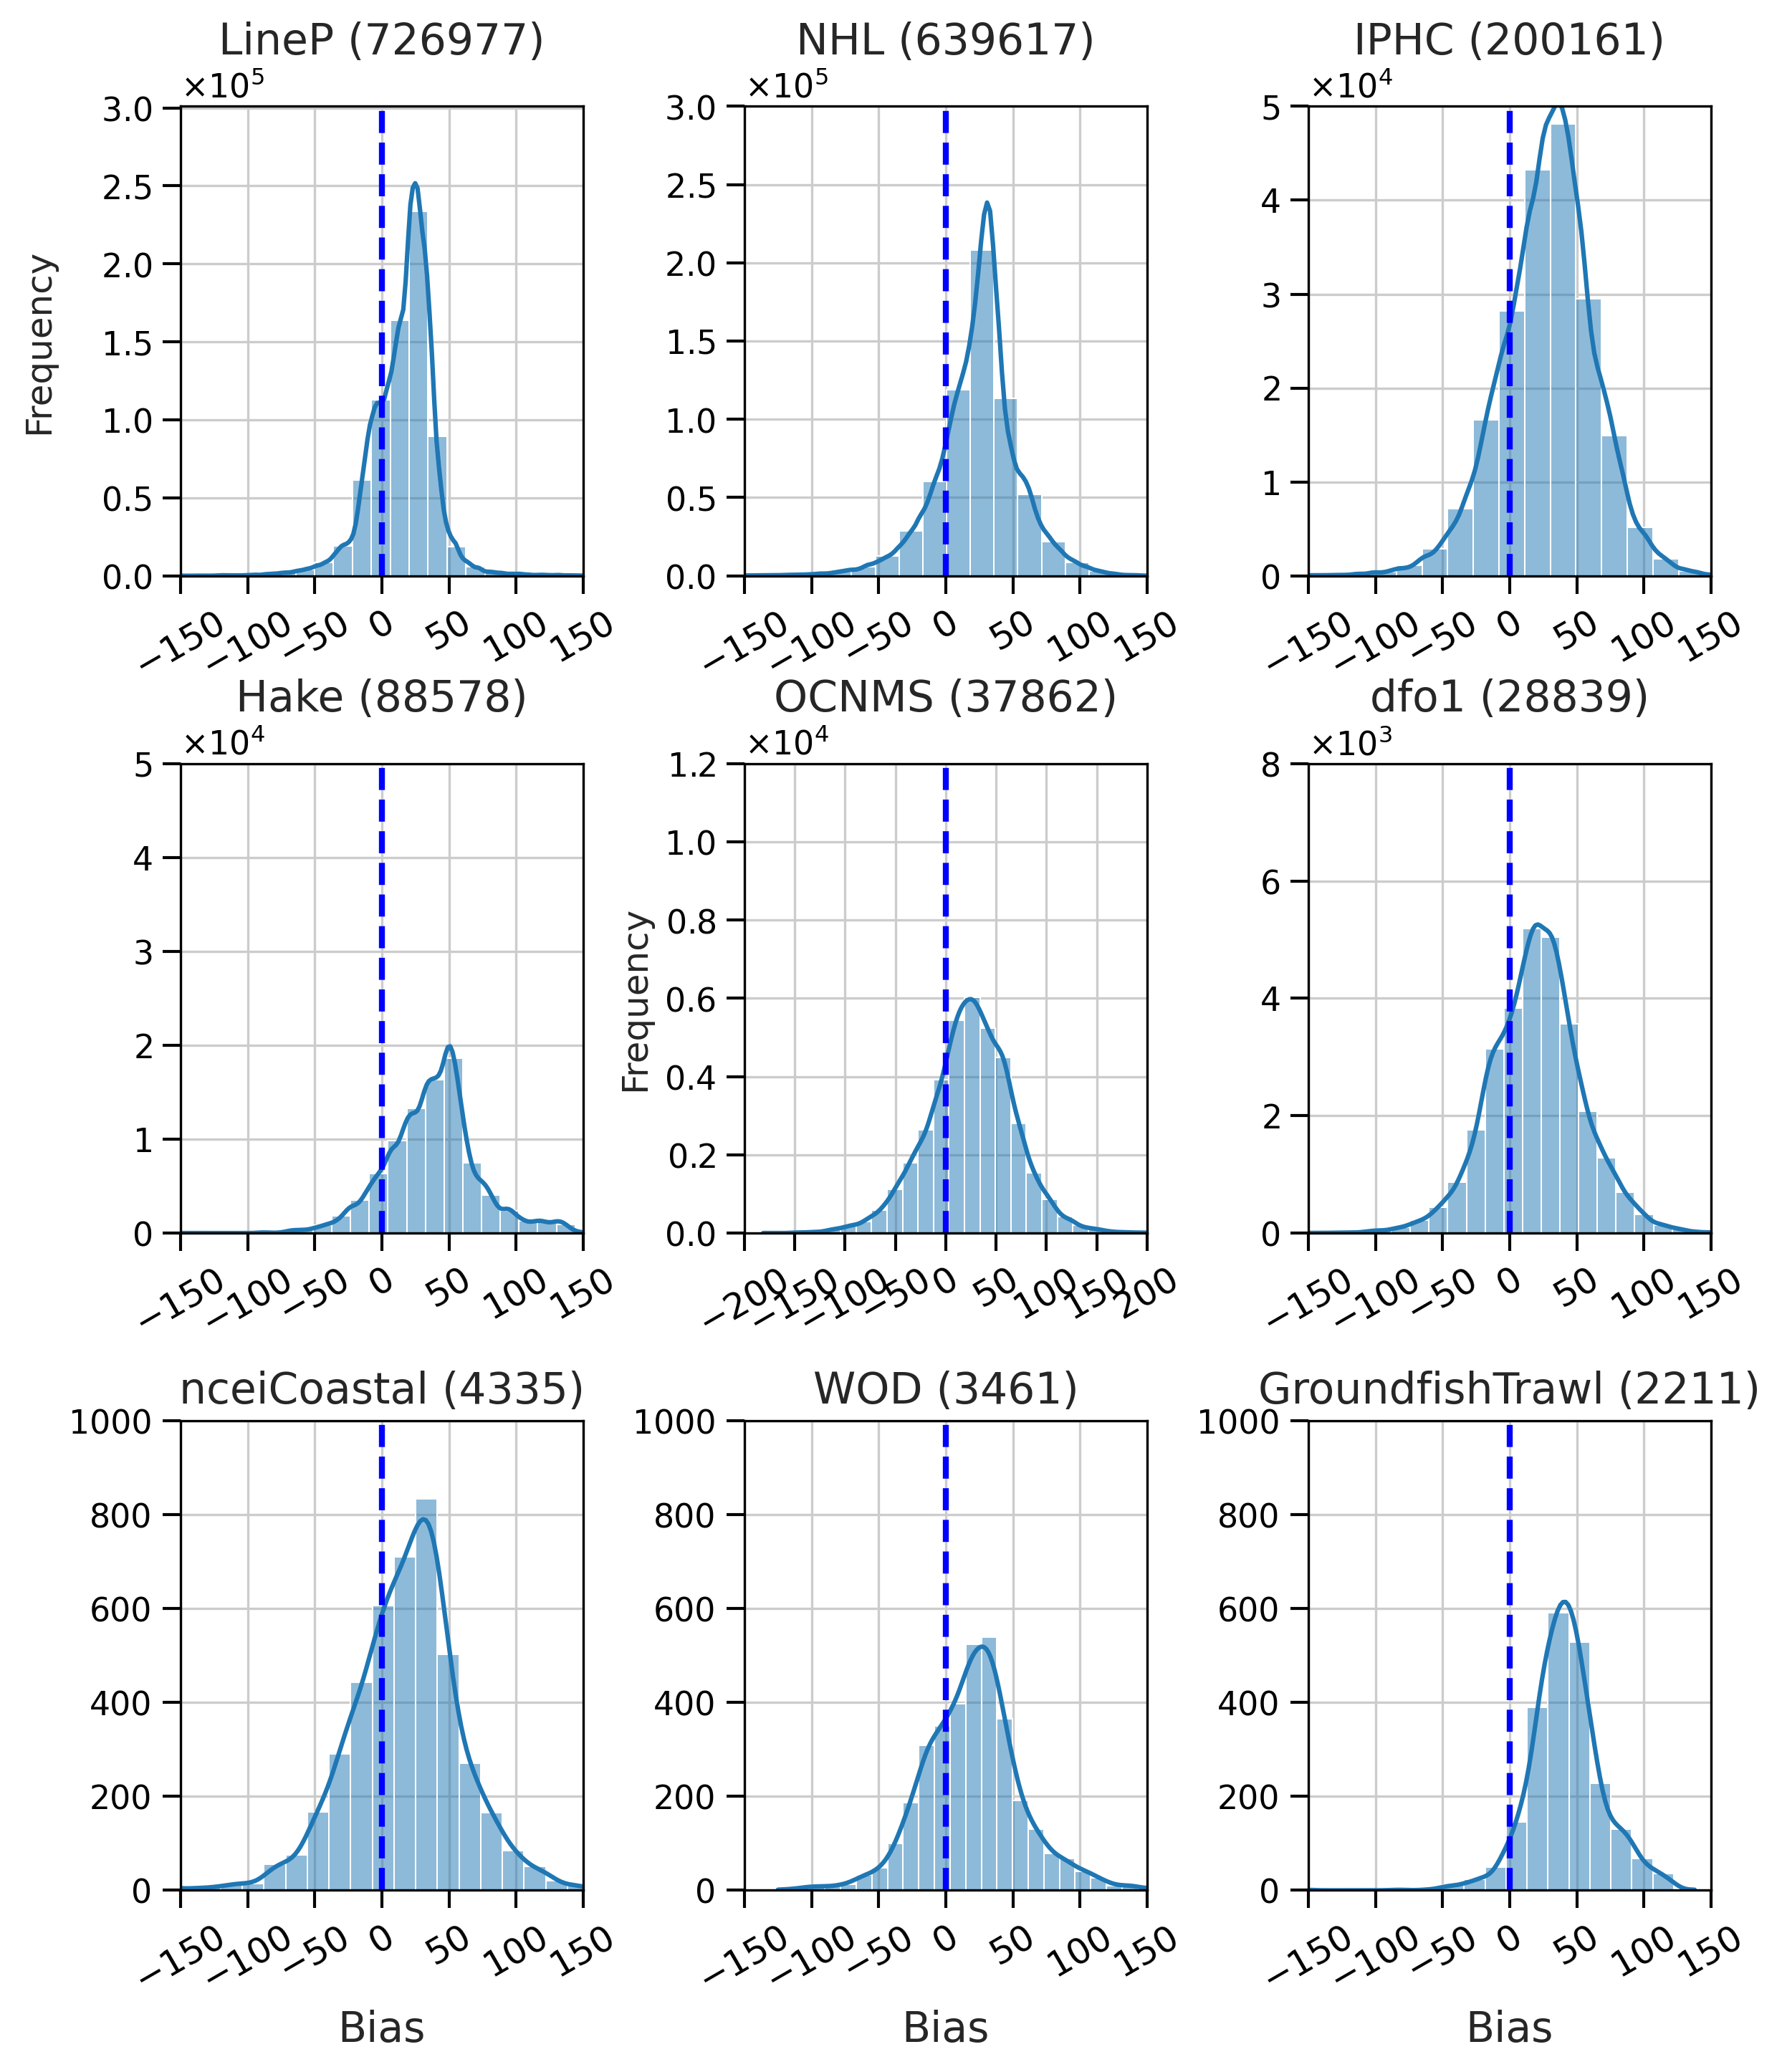

In [9]:
plt.close()

ylim_dict = {
    
    'nceiPNW': [0, 300],
    'WOD': [0, 1000],
    'dfo1': [0, 8000],
    'LineP': [0, 301000],
    'nceiCoastal': [0, 1000],
    'nceiSalish': [0, 80],
    'NHL': [0, 300000],
    'OCNMS': [0, 12000],
    'IPHC': [0, 50000],
    'Hake':[0, 50000],
    'GroundfishTrawl': [0, 1000],
    }

sns.set_style("white") 
# plot the histogram

# source_list = list(df['source'].unique())
source_list = df['source'].value_counts().index.tolist()   # rank the source from high to low
# source_list = source_list[0:-1] # remove Salish
rows, cols = int(len(source_list)/4), int(len(source_list)/4)

fig, axes = plt.subplots(rows, cols, figsize=(8, 10), dpi=300)
# fig.patch.set_facecolor('white')
axes = axes.flatten()  # Flatten the 2D array of axes for easier iteration

for i, source in enumerate(source_list):
    if i < 9:
        sns.histplot(data=df[df['source'] == source], x='bias', ax=axes[i], kde=True, bins=25)
        count = df[df['source'] == source].shape[0]
        axes[i].axvline(0, color='blue', linestyle='--', linewidth=2)  # Vertical line at 0
        axes[i].set_title(f"{source} ({count})")  # Title with count number
        axes[i].set_xlim([-150, 150])
        axes[i].set_xticks(np.arange(-150, 151, 50))  # Set ticks from -200 to 200 in steps of 50
        axes[i].set_ylim(ylim_dict[source])

        for spine in ['top', 'bottom', 'left', 'right']:
            axes[i].spines[spine].set_visible(True)
            axes[i].spines[spine].set_color('black')
            axes[i].spines[spine].set_linewidth(0.8)
        axes[i].grid(True)
        axes[i].set_facecolor('white')
        axes[i].tick_params(axis='x', labelsize=12, rotation=30)
        axes[i].xaxis.set_minor_locator(AutoMinorLocator())
        axes[i].tick_params(axis='x', which='minor', labelbottom=False, length=4, colors='gray')
        axes[i].tick_params(axis='x', which='major', labelbottom=True, length=6, colors='black', width=1)
        axes[i].tick_params(axis='both', which='both', colors='black')
        axes[i].tick_params(left=True, bottom=True, right=False, top=False)

        if i == 8 or  i == 6 or  i == 7:
            axes[i].set_xlabel("Bias")
        else:
            axes[i].set_xlabel('')
            formatter = mtick.ScalarFormatter(useMathText=True)
            formatter.set_scientific(True)
            formatter.set_powerlimits((0, 0))  # force scientific notation
            axes[i].yaxis.set_major_formatter(formatter)

        if i == 0:
            axes[i].set_ylabel("Frequency",fontsize=12, labelpad= 15)
        elif i == 4:
            axes[i].set_ylabel("Frequency",fontsize=12)
            axes[i].set_xlim([-200, 200])
            axes[i].set_xticks(np.arange(-200, 201, 50))
            axes[i].xaxis.set_minor_locator(AutoMinorLocator())
            axes[i].tick_params(axis='x', which='minor', labelbottom=False, length=4, colors='gray')
        else:
            axes[i].set_ylabel('')
    else:
        continue
# plt.tight_layout()
plt.subplots_adjust(
    left=0.08,    # Space between the left edge and the leftmost subplot (0 = no space, 1 = full width)
    right=0.97,   # Space between the right edge and the rightmost subplot
    top=0.93,     # Space between the top edge of the figure and the topmost subplot
    bottom=0.1,  # Space between the bottom edge of the figure and the bottommost subplot
    wspace=0.4,   # Horizontal spacing between subplots (width space)
    hspace=0.4    # Vertical spacing between subplots (height space)
)

plt.savefig(f'{fig_dir}/EDA_histogram_z={Z}.png')
plt.show()

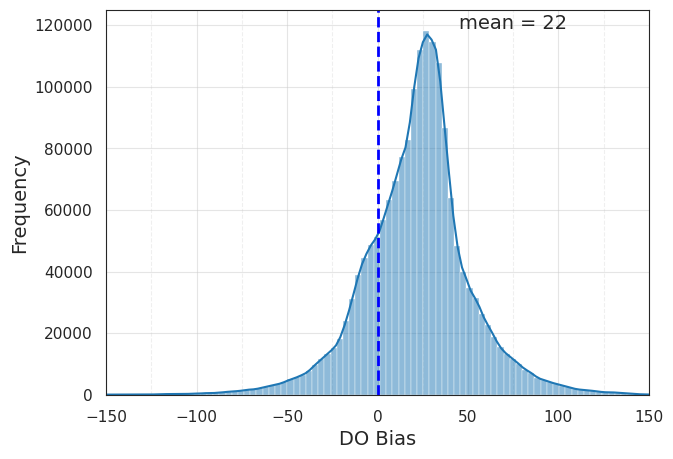

In [10]:
plt.close()
fs = 14
pfun.start_plot(fs=fs, figsize=(7,5))
# fig = plt.figure(figsize=(5, 6), dpi=300)
sns.set_style("white")
sns.histplot(data=df, x='bias', kde=True, bins=140)
plt.axvline(0, color='blue', linestyle='--', linewidth=2)  # Vertical line at 0

ax = plt.gca()

plt.xlim([-150, 150])
plt.ylim([0, 1.25e5])

# major ticks every 50
ax.set_xticks(np.arange(-150, 151, 50))

# minor ticks every 25
ax.set_xticks(np.arange(-150, 151, 25), minor=True)

# optional: make minor ticks visible
ax.tick_params(axis='x', which='major', length=7)
ax.tick_params(axis='x', which='minor', length=4)
# grid for both
ax.grid(which='major', linestyle='-', alpha=0.5)
ax.grid(which='minor', linestyle='--', alpha=0.3)

plt.text(
    0.65, 0.95,
    f"mean = {np.mean(df['bias']):.0f}",
    transform=ax.transAxes
)
plt.ylabel("Frequency")
plt.xlabel("DO Bias")

plt.show()


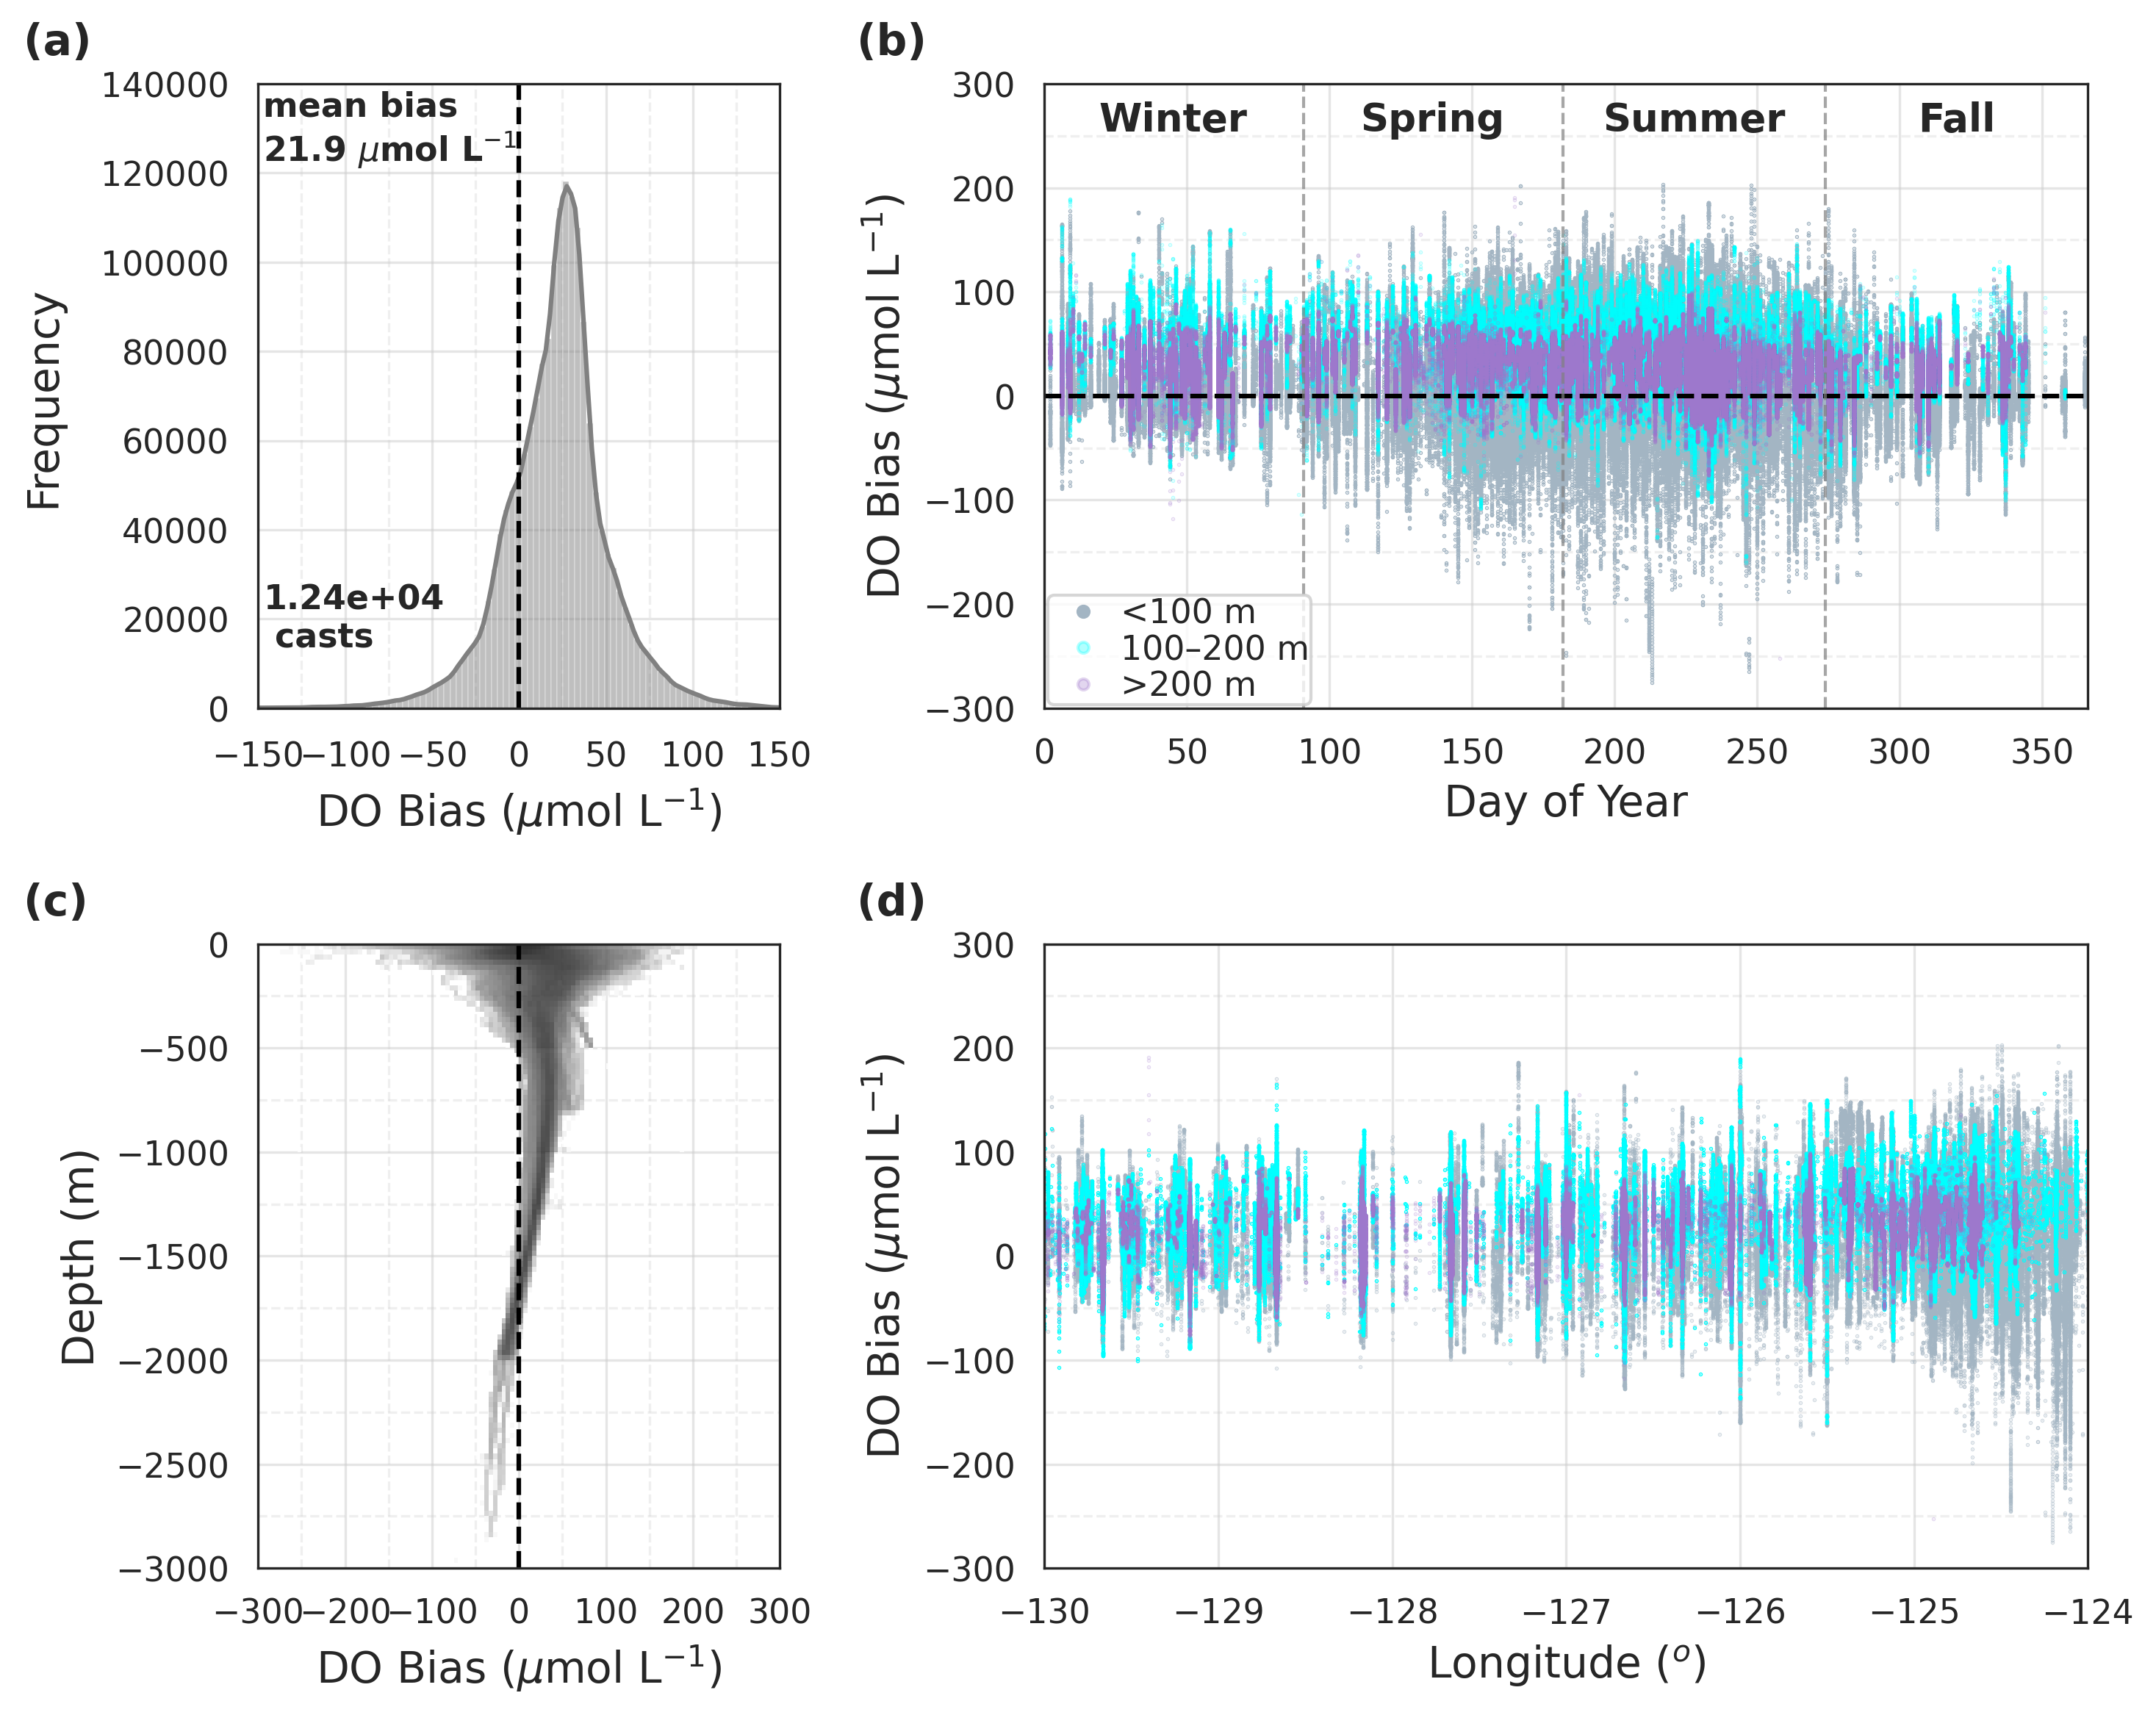

In [11]:
# plot Fig. 4
plt.close('all')

fs = 14
sns.set_style("white")

fig, axes = plt.subplots(2, 2, figsize=(10, 8), dpi=300, gridspec_kw={'width_ratios': [1, 2]})

# -------------------------
# Left: histogram
# -------------------------
ax = axes[0, 0]

sns.histplot(data=df, x='bias', kde=True, bins=140, ax=ax, color='gray')

ax.axvline(0, color='k', linestyle='--', linewidth=1.5)

ax.set_xlim([-150, 150])
ax.set_ylim([0, 1.4e5])

ax.set_xticks(np.arange(-150, 151, 50))
ax.set_xticks(np.arange(-150, 151, 25), minor=True)

ax.tick_params(axis='x', which='major', length=7)
ax.tick_params(axis='x', which='minor', length=4)

ax.grid(which='major', linestyle='-', alpha=0.5)
ax.grid(which='minor', linestyle='--', alpha=0.3)

ax.text(
    0.01, 0.99,
    f"mean bias\n{np.mean(df['bias']):.1f} $\mu$mol L$^{{-1}}$",
    # f"median = {np.median(df['bias']):.0f}",
    transform=ax.transAxes,
    va='top',
    fontsize=11,
    fontweight='bold',
)

ax.text(
    0.01, 0.2,
    f"{df['cid'].nunique():.2e}\n casts",
    # f"median = {np.median(df['bias']):.0f}",
    transform=ax.transAxes,
    va='top',
    fontsize=11,
    fontweight='bold',
)
ax.text(
    -0.45, 1.1,
    '(a)',
    # f"median = {np.median(df['bias']):.0f}",
    transform=ax.transAxes,
    va='top',
    fontsize=fs,
    fontweight='bold',
)
ax.set_ylabel("Frequency", labelpad =12,fontsize=fs)
ax.set_xlabel("DO Bias ($\mu$mol L$^{{-1}}$)",fontsize=fs)
# ax.set_title("Bias Distribution")
# -------------------------
# Right: bias vs time by depth
# -------------------------
ax = axes[0, 1]
# z = -1 * df['z'].values[:, 0]
z = -1 * df['z'].values
bias = df['bias'].values
# time = df['time'].values
time = pd.to_datetime(df['time']).dt.dayofyear.values

alpha = 0.3
ms = 0.6
colors = ['#A3B5C3','cyan','#A078CC', 'darkorange','#FC6C85', 'deepskyblue']

mask = z > -100
ax.plot(
    time[mask], bias[mask],
    '.', color=colors[0],
    # alpha=0.5,
    markersize=ms,
    label='<100 m'
)

mask = (z <= -100) & (z >= -200)
ax.plot(
    time[mask], bias[mask],
    '.', color=colors[1],
    alpha=alpha,
    markersize=ms,
    label='100–200 m'
)

mask = z < -200
ax.plot(
    time[mask], bias[mask],
    '.', color=colors[2],
    alpha=alpha,
    markersize=ms,
    label='>200 m'
)

ax.axhline(0, color='k', linestyle='--', linewidth=1.5)
# ax.text(-13, -10, '0',   ha='center', fontsize=12)
ax.set_xlim([0, 366])
ax.set_ylim([-300, 300])
# y-axis major ticks every 100
ax.set_yticks(np.arange(-300, 301, 100))
# y-axis minor ticks every 50
ax.set_yticks(np.arange(-300, 301, 50), minor=True)
# grids
ax.grid(which='major', linestyle='-', alpha=0.5)
ax.grid(which='minor', linestyle='--', alpha=0.3)
# approximate season boundaries (DOY)
season_lines = [91, 182, 274]

for d in season_lines:
    ax.axvline(
        d,
        color='gray',
        linestyle='--',
        linewidth=1,
        alpha=0.7
    )
ypos = ax.get_ylim()[1] * 0.85
ax.text(45,  ypos, 'Winter', ha='center', fontsize=fs/1.1, fontweight='bold')
ax.text(136, ypos, 'Spring', ha='center', fontsize=fs/1.1, fontweight='bold')
ax.text(228, ypos, 'Summer', ha='center', fontsize=fs/1.1, fontweight='bold')
ax.text(320, ypos, 'Fall',   ha='center', fontsize=fs/1.1, fontweight='bold')

ax.set_xlabel('Day of Year',fontsize=fs)
ax.set_ylabel('DO Bias ($\mu$mol L$^{{-1}}$)',fontsize=fs)
# ax.set_title("Bias Over Time")

ax.legend(markerscale=12,
          loc='lower left',
          fontsize=11,
        borderpad=0.05,      # padding between frame and contents
        labelspacing=0.1,   # vertical spacing between entries
        handletextpad=0.1,  # space between marker and text
        borderaxespad=0.1,   # space between legend and axes edge
       )

ax.text(
    -0.18, 1.1,
    '(b)',
    # f"median = {np.median(df['bias']):.0f}",
    transform=ax.transAxes,
    va='top',
    fontsize=fs,
    fontweight='bold',
)

# bottom left: bias vs depth
# -------------------------
ax = axes[1, 0]

# Define bins
bins_bias = np.arange(-300, 301, 5)
bins_z = np.arange(-3000, 1, 25)

# Density heatmap
h = ax.hist2d(
    bias,
    z,
    bins=[bins_bias, bins_z],
    cmap='Greys',
    norm=LogNorm(vmin=1),
    cmin=1,
    alpha=0.8
)
ax.axvline(0, color='k', linestyle='--', linewidth=1.5)

ax.set_xlim([-300, 300])
ax.set_xticks(np.arange(-300, 301, 100))
ax.set_xticks(np.arange(-300,301, 50), minor=True)

# ax.set_xlim([0, 366])
ax.set_ylim([-3000, 0])
# # y-axis major ticks every 100
# ax.set_yticks(np.arange(-350, 351, 100))
# y-axis minor ticks every 50
ax.set_yticks(np.arange(-3000, 0, 250), minor=True)
# grids
ax.grid(which='major', linestyle='-', alpha=0.5)
ax.grid(which='minor', linestyle='--', alpha=0.3)

ax.set_xlabel('DO Bias ($\mu$mol L$^{{-1}}$)',fontsize=fs)
ax.set_ylabel('Depth (m)',fontsize=fs)
ax.text(
    -0.45, 1.1,
    '(c)',
    # f"median = {np.median(df['bias']):.0f}",
    transform=ax.transAxes,
    va='top',
    fontsize=fs,
    fontweight='bold',
)

ax = axes[1, 1]

lat = df['lat'].values
lon = df['lon'].values

mask = z > -100
ax.plot(
    lon[mask], bias[mask],
    '.',
    color=colors[0],
    alpha=0.5,
    markersize=ms,
    label='<100 m'
)

mask = (z <= -100) & (z >= -200)
ax.plot(
    lon[mask], bias[mask],
    '.', color=colors[1],
    # alpha=alpha,
    markersize=ms,
    label='100–200 m'
)

mask = z < -200
ax.plot(
    lon[mask], bias[mask],
    '.', color=colors[2],
    alpha=alpha,
    markersize=ms,
    label='>200 m'
)
ax.set_xlim([-130, -124])
ax.set_ylim([-300, 300])
ax.set_yticks(np.arange(-300, 301, 100))
ax.set_yticks(np.arange(-300,301, 50), minor=True)
# grids
ax.grid(which='major', linestyle='-', alpha=0.5)
ax.grid(which='minor', linestyle='--', alpha=0.3)
ax.text(
    -0.18, 1.1,
    '(d)',
    # f"median = {np.median(df['bias']):.0f}",
    transform=ax.transAxes,
    va='top',
    fontsize=fs,
    fontweight='bold',
)
ax.set_ylabel('DO Bias ($\mu$mol L$^{{-1}}$)',fontsize=fs)
ax.set_xlabel('Longitude ($^{o}$)',fontsize=fs)


plt.tight_layout()
plt.savefig(f'{fig_dir}/EDA_bias_2x3.png', dpi=300)
plt.show()

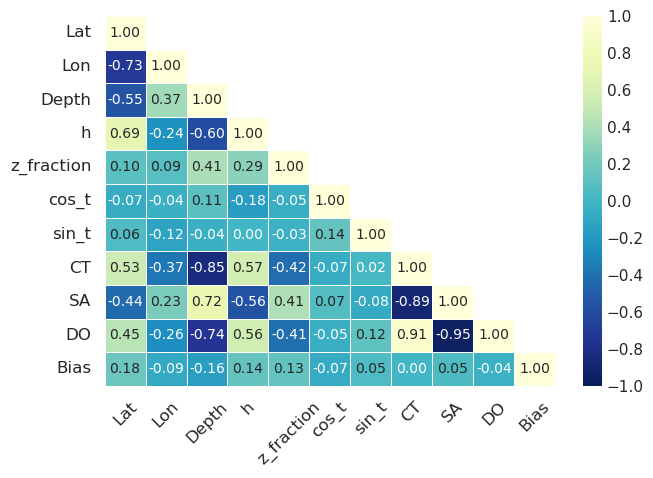

In [12]:
# plot the predictor correlation (Fig. 2)

heatmap = True
if heatmap:
    # Calculate the correlation matrix
    df.drop(['source','time','cid'], axis=1, inplace=True)

    corr_matrix = df.corr()
    sns.set_style("white")
    # mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

    fig, ax = plt.subplots(figsize=(7, 5))

    sns.heatmap(
        corr_matrix,
        mask=mask,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt='.2f',
        annot_kws={"size": 10},
        cmap='YlGnBu_r',
        linewidths=0.5,
        linecolor='white',
        ax=ax
    )

    new_labels = [
        'Lat', 'Lon', 'Depth',
        'h','z_fraction',
        'cos_t',
        'sin_t', 'CT', 'SA',
        'DO',  'Bias'
    ]

    ax.grid(False)
    ax.set_xticklabels(new_labels, fontsize = 12, rotation=45, ha='center')
    ax.set_yticklabels(new_labels, fontsize = 12, rotation=0)
    # colorbar ticks every 0.2
    cbar = ax.collections[0].colorbar
    cbar.set_ticks(np.arange(-1, 1.01, 0.2))
    cbar.ax.tick_params(length=0)
    plt.tight_layout()
    plt.savefig(f'{fig_dir}/EDA_heatmap_z={Z}.png')
    plt.show()



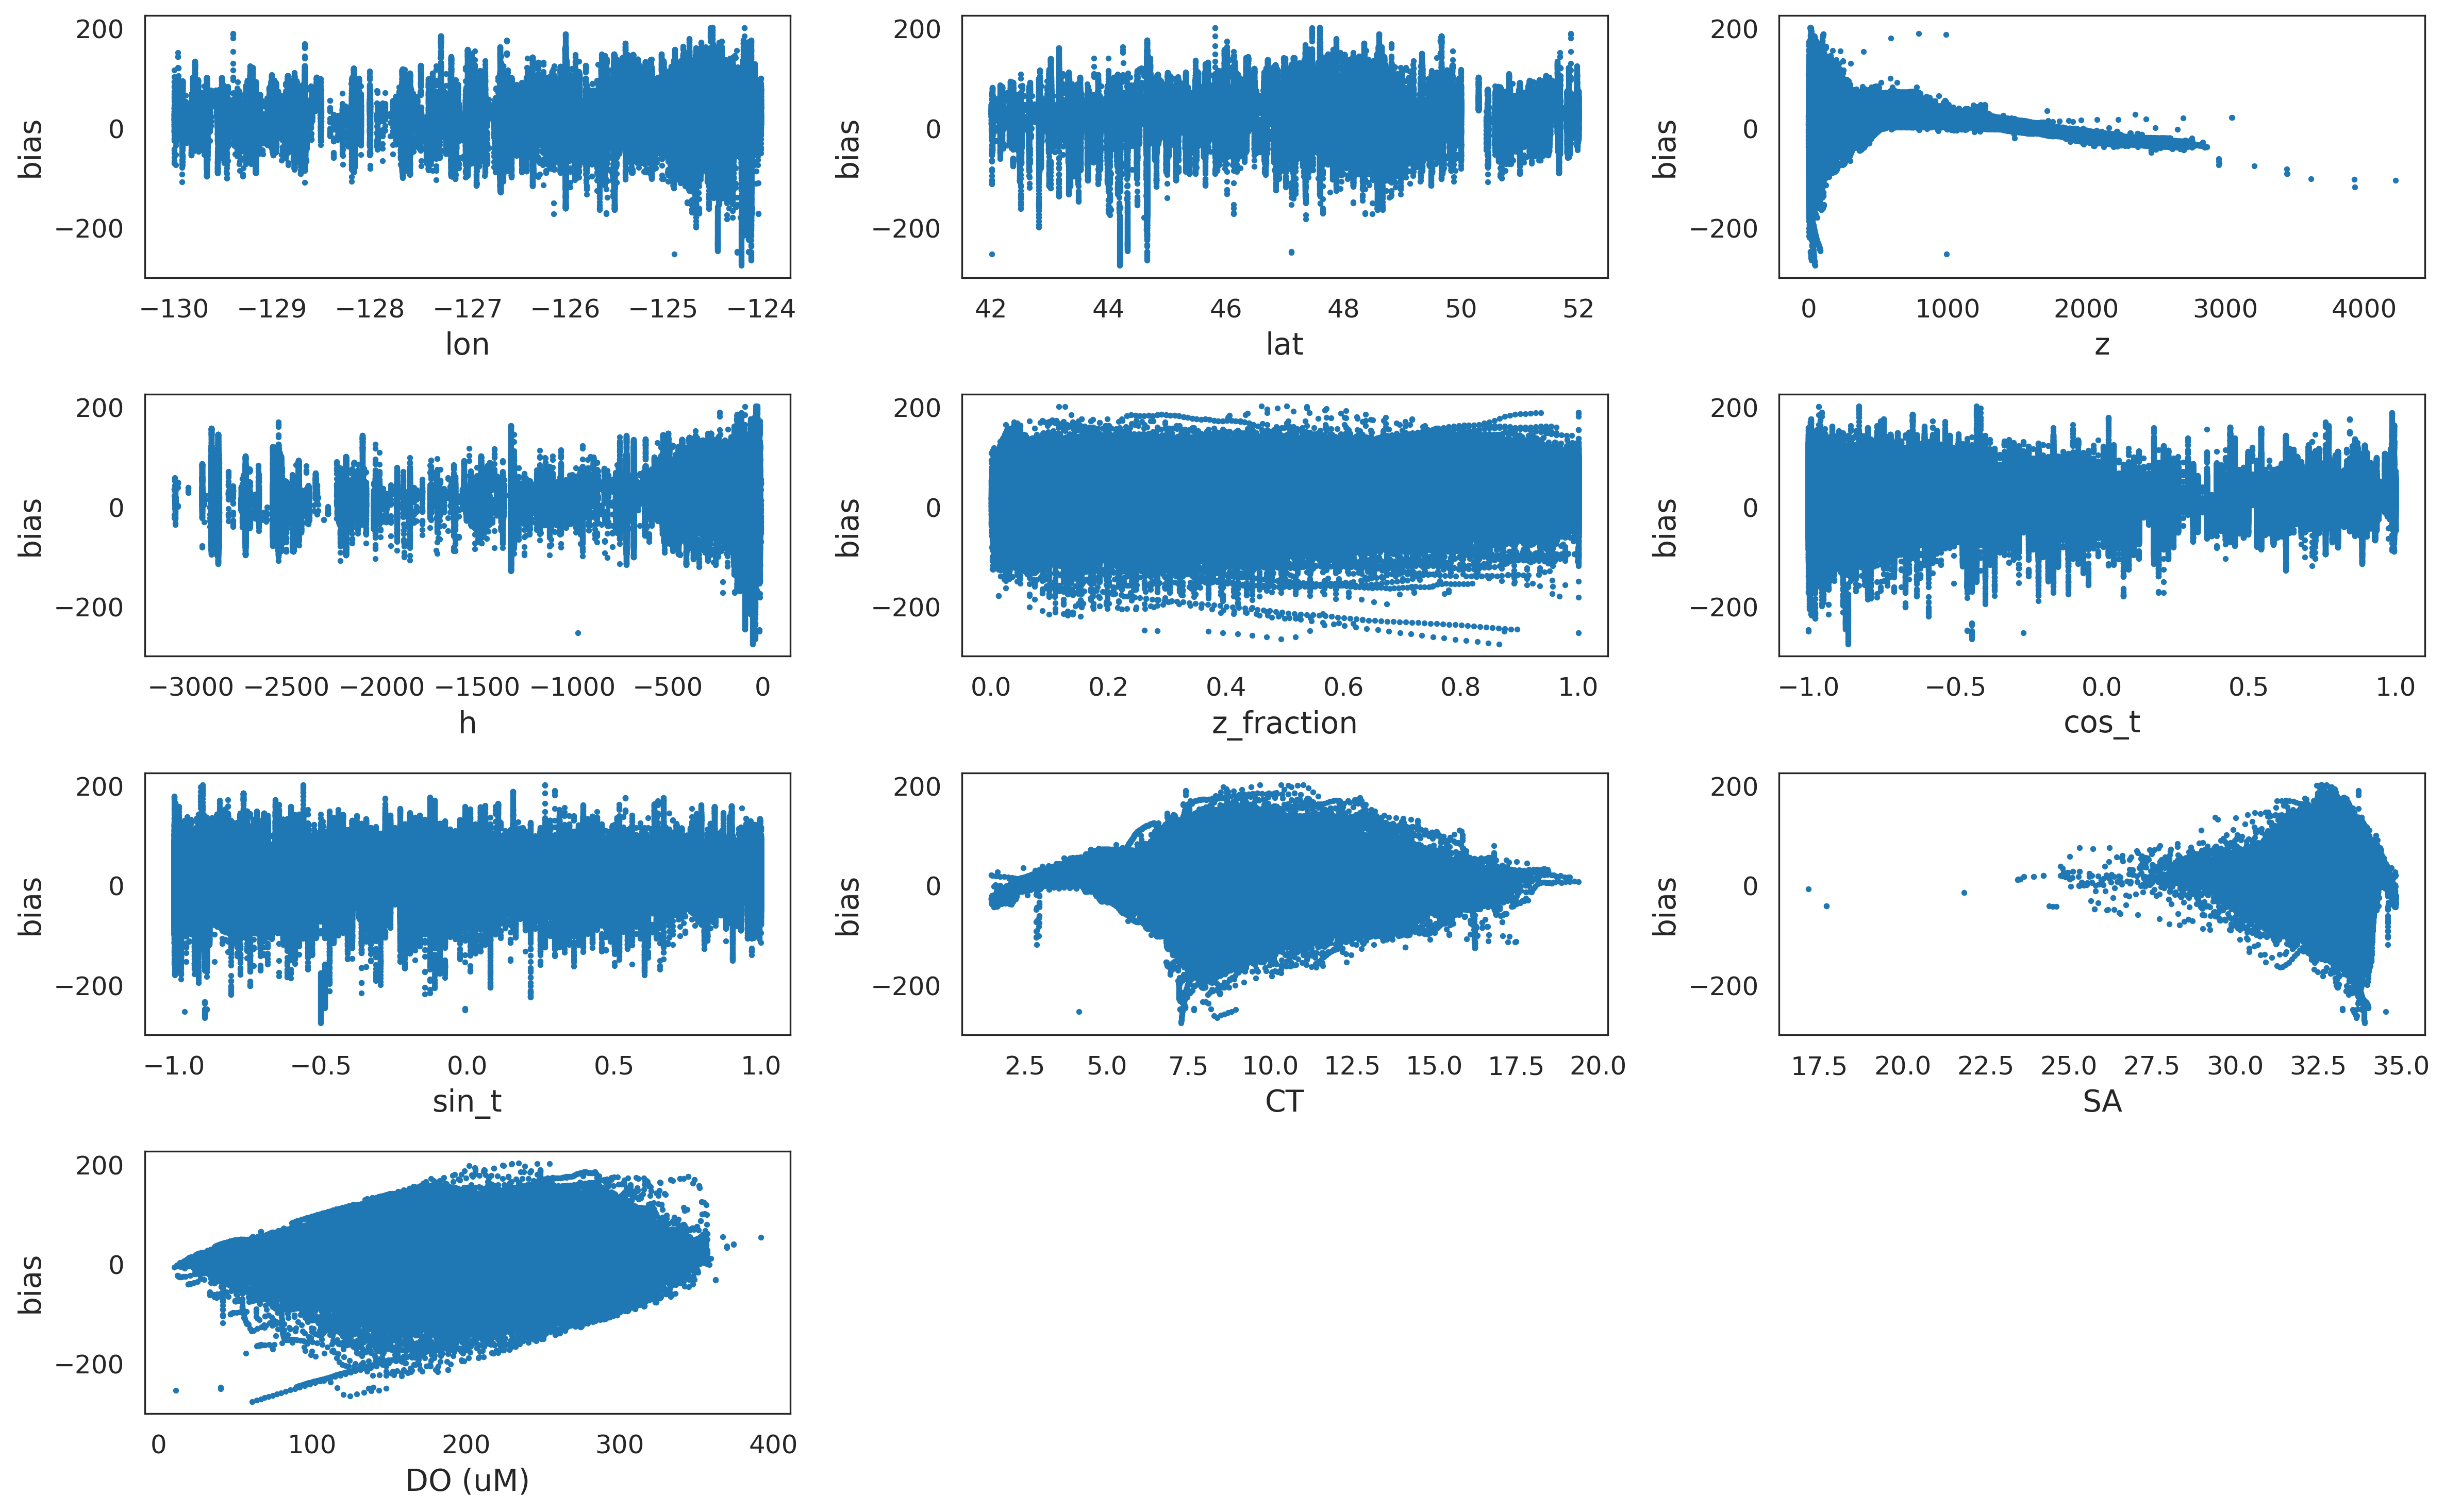

In [13]:
property_property = True
if property_property:
    fig = plt.figure(figsize = (16,10), dpi = 300)
    nrows, ncols = 4, 3

    for i in range(1, df.shape[1]):
        ax = fig.add_subplot(nrows, ncols, i)
        ax.scatter(df.iloc[:,i-1],df.iloc[:,-1], s=3)
        if i == 0:
            ax[i].tick_params(axis='x', labelsize=12, rotation=30)
        ax.set_ylabel(df.columns[-1],fontsize=14)
        ax.set_xlabel(df.columns[i-1],fontsize=14)
        ax.tick_params(axis='x', labelsize=12)
        ax.tick_params(axis='y', labelsize=12)

    plt.tight_layout()
    # plt.savefig(f'{fig_dir}/EDA_property_property_plot_z={Z}.png')
    plt.show()